# Phase 2 — Data Preparation and Exploratory Analysis

## Project Title
Machine Learning based credit card fraud detection

## Research Direction
Advanced Graph Neural Network (GNN)-based credit card
fraud detection using the IEEE-CIS Fraud Detection dataset.

## Objective
Prepare a reliable, leakage-safe and reproducible dataset
for traditional machine learning and graph-based fraud
detection models.

## Phase Scope
- Transaction and identity data integration
- Chronological dataset partitioning
- Training-set exploratory data analysis
- Feature quality and missing-value assessment
- Data leakage prevention
- Numerical and categorical preprocessing
- Reusable preprocessing pipeline
- Prepared dataset validation and storage

## Research Protocol
- Preserve the original raw dataset.
- Fit preprocessing using training data only.
- Prevent future information leakage.
- Keep identical timestamps within the same partition.
- Reserve the held-out test set for final evaluation.
- Preserve attributes required for graph construction.
- Ensure independent notebook reproducibility.


In [8]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

current_directory=Path.cwd()

project_root = (
    current_directory.parent
    if current_directory.name=="notebooks"
    else current_directory
)
raw_dir = project_root/"data"/"raw"
assert raw_dir.is_dir(),"Raw data directory not found."

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Project root:", project_root)
print("Raw data directory:", raw_dir)
print("Phase 2 environment setup successful.")

Python version: 3.14.8
Python executable: c:\Users\rakes\Machine Learning\ml-env\Scripts\python.exe
Pandas version: 3.0.6
NumPy version: 2.5.4
Project root: c:\Users\rakes\Machine Learning\Minor Project\credit-card-fraud-detection
Raw data directory: c:\Users\rakes\Machine Learning\Minor Project\credit-card-fraud-detection\data\raw
Phase 2 environment setup successful.


## 2.2 Transaction Dataset Loading and Schema Validation

Load the complete labeled transaction dataset for data
integration, chronological partitioning and subsequent
feature preparation.

Validate the dataset dimensions and required transaction
attributes against the established Phase 1 findings.

Preserve all original columns to support traditional
machine learning and future graph construction.

No feature transformations are applied at this stage.


In [9]:
txn_file = raw_dir/"train_transaction.csv"
txn_data = pd.read_csv(
    txn_file,
    low_memory=False
)
required_columns = [
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "card2",
    "card5"
]
assert txn_data.shape==(590540, 394),\
    "Unexpected transaction dataset dimensions."
assert all(
    column in txn_data.columns
    for column in required_columns
),"Required transaction columns are missing."

print("Transaction dataset shape:", txn_data.shape)
print("Required columns: All available")
print(
    "Memory usage (MiB):",
    round(txn_data.memory_usage(deep=True).sum() / 1024**2, 2)
)
print("Transaction dataset validation successful.")

Transaction dataset shape: (590540, 394)
Required columns: All available
Memory usage (MiB): 2062.07
Transaction dataset validation successful.


## 2.3 Identity Dataset Loading and Validation

Load the labeled identity dataset containing anonymized
identity-related and device-related attributes.

Validate dataset dimensions, required columns, identifier
completeness, identifier uniqueness and compatibility
with the transaction dataset.

Measure identity coverage and memory consumption to
establish the feasibility of transaction-identity integration.

Identity attributes are treated as anonymized observations,
not verified customer identities.

No merging or feature transformations are performed
at this stage.


In [10]:
id_file = raw_dir/"train_identity.csv"
id_data = pd.read_csv(
    id_file, 
    low_memory=False
)
required_identity_columns = [
    "TransactionID",
    "DeviceType",
    "DeviceInfo"
]
assert id_data.shape == (144233, 41), \
    "Unexpected identity dataset dimensions."
assert all(
    column in id_data.columns
    for column in required_identity_columns
), "Required identity columns are missing."
missing_identity_ids = id_data["TransactionID"].isna().sum()
duplicate_identity_ids = id_data["TransactionID"].duplicated().sum()
unmatched_identity_ids = (
    ~id_data["TransactionID"].isin(
        txn_data["TransactionID"]
    )
).sum()
assert missing_identity_ids==0, "Missing identity identifiers found."
assert duplicate_identity_ids==0, "Duplicate identity identifiers found."
assert unmatched_identity_ids==0, "Unmatched identity identifiers found."

id_coverage = len(id_data)/len(txn_data)*100

print("Identity dataset shape:", id_data.shape)
print("Required identity columns: All available")
print("Missing TransactionIDs:", missing_identity_ids)
print("Duplicate TransactionIDs:", duplicate_identity_ids)
print("Unmatched TransactionIDs:", unmatched_identity_ids)
print("Identity coverage (%):", round(id_coverage, 2))
print(
    "Memory usage (MiB):",
    round(id_data.memory_usage(deep=True).sum() / 1024**2, 2)
)
print("Identity dataset validation successful.")

Identity dataset shape: (144233, 41)
Required identity columns: All available
Missing TransactionIDs: 0
Duplicate TransactionIDs: 0
Unmatched TransactionIDs: 0
Identity coverage (%): 24.42
Memory usage (MiB): 143.14
Identity dataset validation successful.


## 2.4 Transaction and Identity Dataset Integration

Merge transaction and identity data using TransactionID
while preserving all labeled transactions.

In [11]:
integrated_data = txn_data.merge(
    id_data,
    on="TransactionID",
    how="left",
    validate="one_to_one",
    sort=False
)

print("Integrated dataset shape:", integrated_data.shape)

Integrated dataset shape: (590540, 434)


In [12]:
preserved_cols = ["TransactionID", "isFraud", "TransactionDT"]

info_preserved = integrated_data[preserved_cols].equals(
    txn_data[preserved_cols]
)

print("Original transaction information preserved:", info_preserved)

Original transaction information preserved: True


## 2.5 Chronological Training, Validation and Test Partitions

Partition the integrated dataset chronologically using
TransactionDT to simulate historical model training
and future fraud prediction.

Using an approximately 70:15:15 split while ensuring
that identical timestamps remain in the same partition.

In [13]:
is_sorted = integrated_data["TransactionDT"].is_monotonic_increasing
assert is_sorted, "Transactions are not chronologically ordered."
print("Transactions chronologically ordered:", is_sorted)

Transactions chronologically ordered: True


In [14]:
n = len(integrated_data)
train_cut = integrated_data["TransactionDT"].iloc[
    int(n*0.70)
]
val_cut = integrated_data["TransactionDT"].iloc[
    int(n * 0.85)
]
print("Total transactions:", n)
print("Train cutoff:", train_cut)
print("Validation cutoff:", val_cut)

Total transactions: 590540
Train cutoff: 10438003
Validation cutoff: 13151880


In [16]:
time = integrated_data["TransactionDT"]
train_data = integrated_data[
    time < train_cut
]
val_data = integrated_data[
    (time >= train_cut)&(time < val_cut)
]
test_data = integrated_data[
    time >= val_cut
]
print("Train shape:", train_data.shape)
print("Validation shape:", val_data.shape)
print("Test shape:", test_data.shape)

Train shape: (413378, 434)
Validation shape: (88581, 434)
Test shape: (88581, 434)


## 2.6 Training-set Exploratory Data Analysis

Analyze fraud distribution, transaction patterns and
feature relationships using the training partition only.

In [18]:
fraud_counts = train_data["isFraud"].value_counts().sort_index()
fraud_pct = train_data["isFraud"].value_counts(
    normalize=True
).sort_index()*100

print("Class distribution:")
print(fraud_counts)
print("\nClass percentage:")
print(fraud_pct.round(2))

Class distribution:
isFraud
0    398840
1     14538
Name: count, dtype: int64

Class percentage:
isFraud
0    96.48
1     3.52
Name: proportion, dtype: float64


1. Training Class Distribution


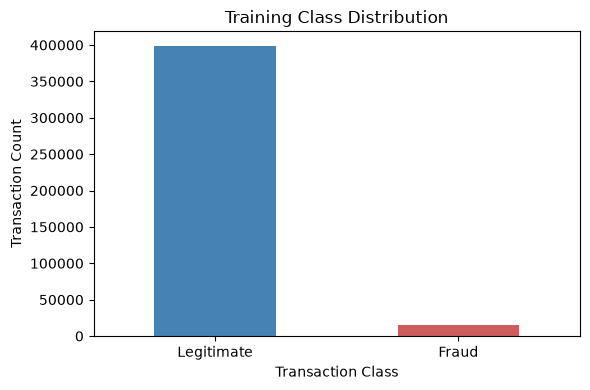

In [19]:
import matplotlib.pyplot as plt

fraud_counts.plot(
    kind = 'bar',
    color = ['steelblue','indianred'],
    figsize = (6,4),
    rot = 0
)
plt.title('Training Class Distribution')
plt.xlabel('Transaction Class')
plt.ylabel('Transaction Count')
plt.xticks(
    [0,1] , ['Legitimate','Fraud']
)
plt.tight_layout()
plt.show()

2. Comparing transaction amounts between legitimate and fraudulent transactions to investigate whether TransactionAmt could be a useful predictive feature.

In [21]:
amt_stats = train_data.groupby('isFraud')['TransactionAmt'].describe()
display(
    amt_stats.round(2)
)

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,398840.0,134.20,238.76,0.25,43.95,68.95,125.0,31937.39
1,14538.0,145.64,216.15,0.29,34.75,75.00,171.0,4191.00


3. Comparing transaction amount distributions between the two classes through a box plot.

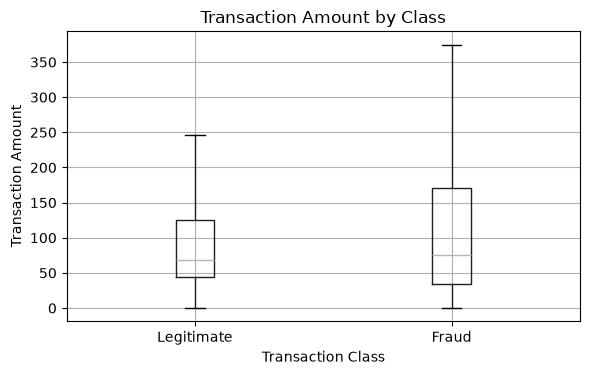

In [22]:
train_data.boxplot(
    column = 'TransactionAmt',
    by = 'isFraud',
    showfliers = False,
    figsize = (6,4)
)

plt.title('Transaction Amount by Class')
plt.suptitle('')
plt.xlabel('Transaction Class')
plt.ylabel('Transaction Amount')
plt.xticks(
    [1,2],
    ['Legitimate','Fraud']          
)
plt.tight_layout()
plt.show()

4. TransactionDT represents elapsed time in seconds. 
Converting these timestamps into relative day numbers and calculating the daily fraud rate to investigate how fraud patterns change over time.

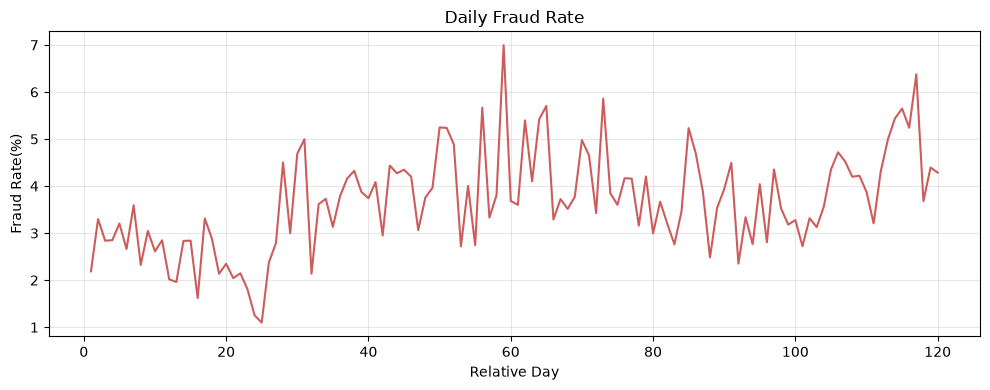

In [23]:
days = train_data['TransactionDT']//86400
daily_fraud = train_data.groupby(days)['isFraud'].mean()*100
daily_fraud.plot(
    figsize = (10 , 4), 
    color = 'indianred'
)

plt.title('Daily Fraud Rate')
plt.xlabel('Relative Day')
plt.ylabel('Fraud Rate(%)')
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

5. Examining the relationship between ProductCD and fraud.                                      
 -- ProductCD is an anonymized categorical attribute representing product codes in the dataset.                                                                                     
We will calculate the total transactions, fraudulent transactions and fraud rate for each product category.

In [ ]:
product_stats = train_data.groupby("ProductCD")["isFraud"].agg(
    total="count",
    fraud="sum",
    fraud_rate="mean"
)

product_stats["fraud_rate"] *= 100
display(product_stats.round(2))

,total,fraud,fraud_rate
ProductCD,,,
C,50006,5588,11.17
H,28112,1270,4.52
R,30144,1054,3.50
S,7205,435,6.04
W,297911,6191,2.08


## 2.7 Feature Quality and Missing-Value Analysis

Assess missing values, feature types and feature quality
using the training dataset.

In [ ]:
missing = train_data.isna().sum()
missing_pct = (missing/len(train_data))*100
missing_stats = pd.DataFrame({
    "missing": missing,
    "missing_pct": missing_pct.round(2)
})
missing_stats = missing_stats.sort_values(
    "missing_pct", 
    ascending=False
)
display(missing_stats.head(10))

,missing,missing_pct
id_24,409769,99.13
id_23,409439,99.05
id_21,409443,99.05
id_08,409448,99.05
id_07,409448,99.05
id_22,409439,99.05
id_25,409463,99.05
id_26,409445,99.05
id_27,409439,99.05
D7,386632,93.53


In [26]:
missing_summary = pd.cut(
    missing_pct,
    bins=[-1, 0, 25, 50, 75, 90, 100],
    labels=["0%", "0-25%", "25-50%", "50-75%", "75-90%", "90-100%"]
).value_counts(sort=False)

display(missing_summary)

0%          63
0-25%      119
25-50%      23
50-75%     105
75-90%     112
90-100%     12
Name: count, dtype: int64

In [27]:
dtype_counts = train_data.dtypes.value_counts()
display(dtype_counts)

float64    399
str         31
int64        4
Name: count, dtype: int64

In [28]:
unique_counts = train_data.nunique()
constant_cols = unique_counts[
    unique_counts == 1
].index.tolist()

print("Constant columns:", len(constant_cols))
print(constant_cols)

Constant columns: 1
['V107']


## 2.8 Data Leakage Identification and Prevention

Separate the target, transaction identifier and timestamp
from candidate model features.
Preserve metadata for chronological evaluation and
graph construction.

In [29]:
target = "isFraud"
meta_cols = [
    "TransactionID",
    "TransactionDT"
]
feature_cols = train_data.columns.drop(
    [target] + meta_cols
).tolist()

print("Target:", target)
print("Metadata:", meta_cols)
print("Candidate features:", len(feature_cols))

Target: isFraud
Metadata: ['TransactionID', 'TransactionDT']
Candidate features: 431


### Leakage Prevention Rules

- Exclude the target and raw metadata from model inputs.
- Fit preprocessing and feature selection on training data only.
- Apply fitted transformations to validation and test data.
- Preserve the chronological partition boundaries.
- Construct temporal features using historical information only.
- Prevent future transactions from influencing graph predictions.
- Reserve test data for final model evaluation.
- Review feature availability at prediction time.

In [30]:
assert target not in feature_cols
assert not set(meta_cols).intersection(feature_cols)
assert train_data.columns.equals(val_data.columns)
assert train_data.columns.equals(test_data.columns)

print("Feature validation passed.")

Feature validation passed.


## 2.9 Missing-Value Treatment

Define missing-value treatment strategies using
training data only.

Preserve original attributes required for graph construction
and prevent information leakage during imputation.

In [31]:
empty_cols = missing_pct[feature_cols][
    missing_pct[feature_cols] == 100
].index.tolist()

print("Entirely missing features:", len(empty_cols))
print(empty_cols)

Entirely missing features: 0
[]
